In [23]:
import pandas as pd
df=pd.read_csv("netflix_titles.csv")
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [25]:
df.info()
df.shape
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [27]:
# check missing values in each column
df.isnull().sum() 


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [29]:
df = df.dropna()

In [35]:
df['rating'] = df['rating'].astype(object)

object
7     TV-MA
8     TV-14
9     PG-13
12    TV-MA
24    TV-14
Name: rating, dtype: object


In [178]:
import warnings
warnings.filterwarnings('ignore')
rating_mode = df['rating'].mode()[0]
df['rating'].fillna(rating_mode, inplace=True)
director_mode = df['director'].mode()[0]
df['director'].fillna(director_mode, inplace=True)
print(df[['rating','director']].isnull().sum())


rating      0
director    0
dtype: int64


In [41]:
df = df.drop_duplicates()

In [43]:
print(df['rating'].unique())
rating_mapping = {
    'TV-MA': 0,
    'TV-14': 1,
    'TV-PG': 2,
    'R': 3,
    'PG-13': 4,
    'TV-Y7': 5,
    'PG': 6,
    'TV-Y': 7,
    'G': 8,
    'NC-17': 9,
    'NR': 10,
    'UR': 11
}
df['rating_encoded'] = df['rating'].map(rating_mapping)




['TV-MA' 'TV-14' 'PG-13' 'PG' 'R' 'TV-PG' 'G' 'TV-Y7' 'TV-G' 'TV-Y'
 'NC-17' 'NR' 'TV-Y7-FV' 'UR']


In [45]:
print(df.columns)

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'rating_encoded'],
      dtype='object')


In [53]:
#MinMaxScaler Normalization
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
cols = ['release_year']
df[cols] = scaler.fit_transform(df[cols])

In [57]:
#Z-Score Normalization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cols = ['release_year']
df[cols] = scaler.fit_transform(df[cols])

In [59]:
print(df.head())

   show_id     type                          title             director  \
7       s8    Movie                        Sankofa         Haile Gerima   
8       s9  TV Show  The Great British Baking Show      Andy Devonshire   
9      s10    Movie                   The Starling       Theodore Melfi   
12     s13    Movie                   Je Suis Karl  Christian Schwochow   
24     s25    Movie                          Jeans           S. Shankar   

                                                 cast  \
7   Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...   
8   Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...   
9   Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...   
12  Luna Wedler, Jannis Niewöhner, Milan Peschel, ...   
24  Prashanth, Aishwarya Rai Bachchan, Sri Lakshmi...   

                                              country          date_added  \
7   United States, Ghana, Burkina Faso, United Kin...  September 24, 2021   
8                                      United Kingdo

In [61]:
print(df.columns)

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'rating_encoded'],
      dtype='object')


In [63]:
df = df.drop('type', axis=1)

In [66]:
print(df.dtypes)

show_id            object
title              object
director           object
cast               object
country            object
date_added         object
release_year      float64
rating             object
duration           object
listed_in          object
description        object
rating_encoded    float64
dtype: object


In [182]:
df=df.dropna(subset=['listed_in'])
df['genre_list'] = df['listed_in'].apply(lambda x: [genre.strip() for genre in x.split(',')])

In [186]:
genre_df = df.explode('genre_list')
top_genres = genre_df['genre_list'].value_counts().head(10)
print(top_genres)

genre_list
International Movies        2369
Dramas                      2293
Comedies                    1553
Action & Adventure           806
Independent Movies           740
Romantic Movies              579
Thrillers                    547
Children & Family Movies     503
Documentaries                391
Horror Movies                336
Name: count, dtype: int64


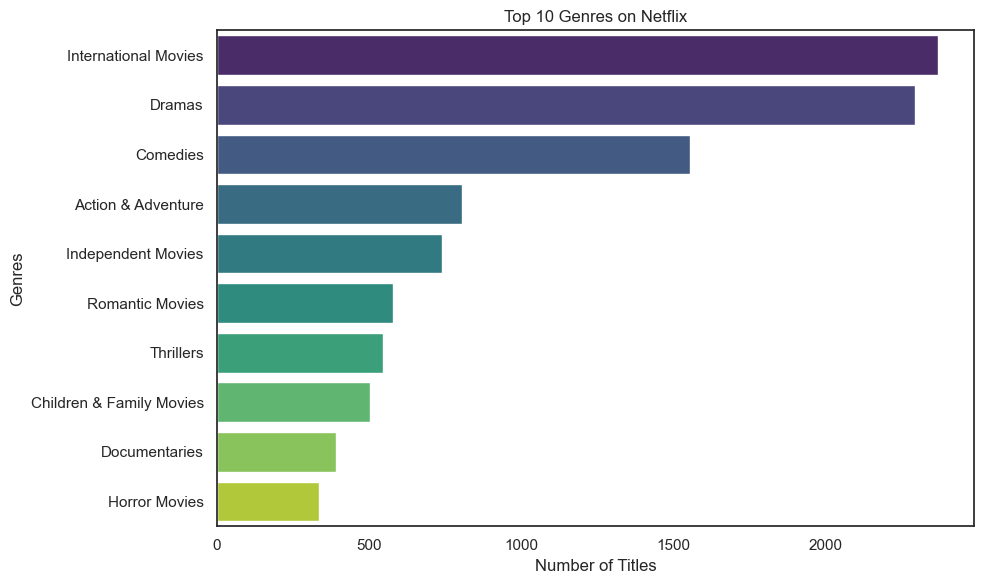

In [188]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, palette='viridis')
plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genres')
plt.tight_layout()
plt.show()

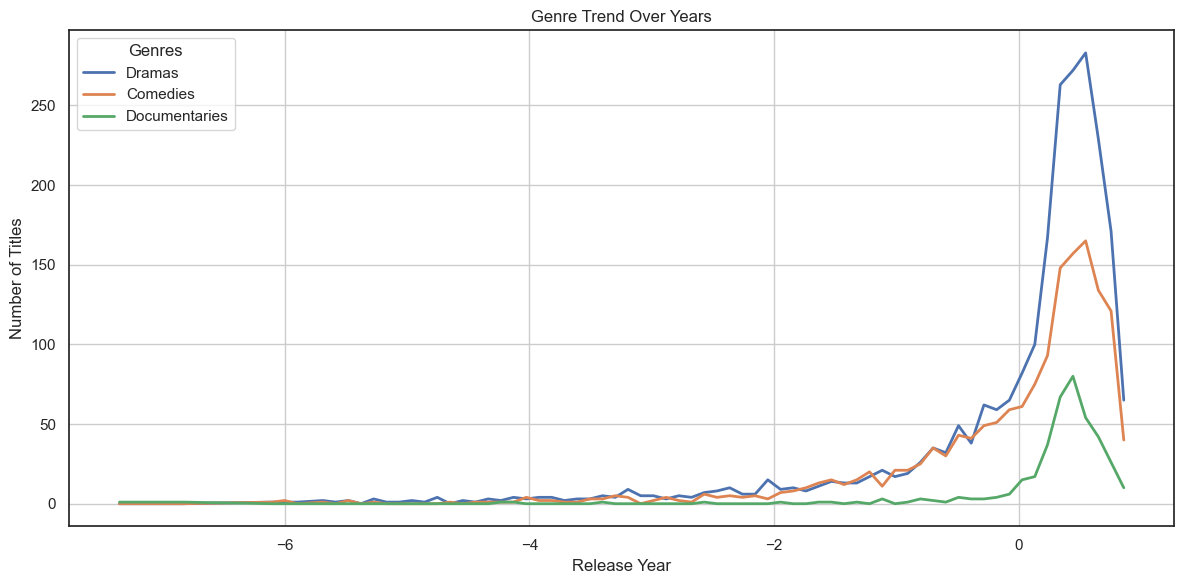

In [190]:
genre_trend = genre_df.dropna(subset=['release_year']).groupby(['release_year', 'genre_list']).size().unstack().fillna(0)
selected_genres = ['Dramas', 'Comedies', 'Documentaries']
genre_trend[selected_genres].plot(figsize=(12,6), linewidth=2)
plt.title('Genre Trend Over Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend(title="Genres")
plt.grid(True)
plt.tight_layout()
plt.show()

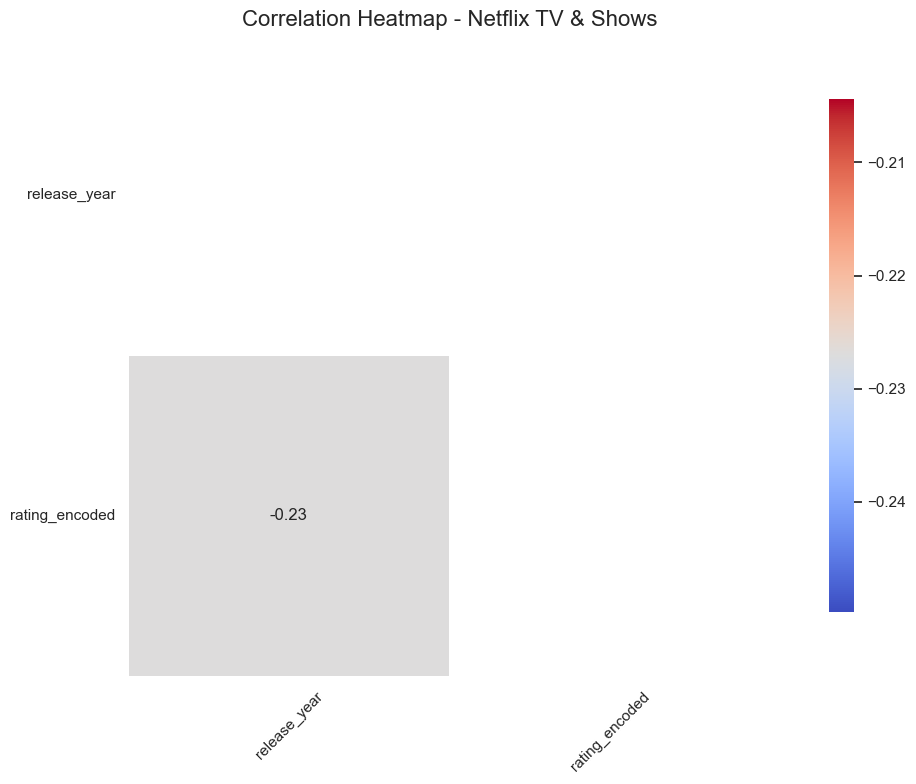

In [68]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
sns.set(style="white")
numeric_df = df.select_dtypes(include='number')
corr_matrix = numeric_df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    mask=mask,  
    annot=True,     
    fmt=".2f",      
    cmap="coolwarm",
    linewidths=0.5,   
    square=True,      
    cbar_kws={"shrink": 0.8}  
)
plt.title("Correlation Heatmap - Netflix TV & Shows", fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [70]:
df.select_dtypes(exclude='number').columns


Index(['show_id', 'title', 'director', 'cast', 'country', 'date_added',
       'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [72]:
df.columns

Index(['show_id', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'rating_encoded'],
      dtype='object')

In [120]:
df = df.dropna(subset=['release_year']) 
df['realese_year'] = df['release_year'].astype(int)
X = df[['release_year']]
y = df['rating']              

In [122]:
#split Train and test data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.5, random_state=44)

In [124]:
X_train.shape

(2666, 1)

In [126]:
X_test.shape

(2666, 1)

In [128]:
y_test.shape

(2666,)

In [130]:
y_train.shape

(2666,)

In [132]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()
knn.fit(X_train,y_train)

KNeighborsClassifier()

In [134]:
from sklearn.linear_model import LogisticRegression
ob=LogisticRegression()
ob.fit(X_train,y_train)

LogisticRegression()

In [136]:
from sklearn.ensemble import RandomForestClassifier
ob=RandomForestClassifier()
ob.fit(X_train,y_train)

RandomForestClassifier()

In [138]:
from sklearn import metrics 
y_pred=ob.predict(X_test)
print(metrics.accuracy_score(y_test,y_pred)*100)

35.9714928732183


In [140]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
y_pred_logreg = logreg.predict(X_test)
logreg_acc = accuracy_score(y_test, y_pred_logreg)
print(f"Logistic Regression Accuracy: {logreg_acc * 100:.2f}%")


Logistic Regression Accuracy: 35.30%


In [142]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
rf_acc = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {rf_acc * 100:.2f}%")


Random Forest Accuracy: 35.93%


In [144]:
from sklearn.svm import SVC
ob=SVC()
ob.fit(X_train,y_train)

SVC()

In [146]:
from sklearn.svm import SVC
svc = SVC()
svc.fit(X_train, y_train)
y_pred_svc = svc.predict(X_test)
svc_acc = accuracy_score(y_test, y_pred_svc)
print(f"SVC (SVM) Accuracy: {svc_acc * 100:.2f}%")


SVC (SVM) Accuracy: 37.96%


In [148]:
from sklearn.tree import DecisionTreeClassifier
ob=DecisionTreeClassifier()
ob.fit(X_train,y_train)

DecisionTreeClassifier()

In [150]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
dt_acc = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {dt_acc * 100:.2f}%")

Decision Tree Accuracy: 36.01%


In [152]:
print("\n📊 Model Accuracy Summary:")
print(f"KNN Accuracy: {accuracy_score(y_test, knn.predict(X_test)) * 100:.2f}%")
print(f"Logistic Regression Accuracy: {logreg_acc * 100:.2f}%")
print(f"Random Forest Accuracy: {rf_acc * 100:.2f}%")
print(f"SVC Accuracy: {svc_acc * 100:.2f}%")
print(f"Decision Tree Accuracy: {dt_acc * 100:.2f}%")


📊 Model Accuracy Summary:
KNN Accuracy: 28.54%
Logistic Regression Accuracy: 35.30%
Random Forest Accuracy: 35.93%
SVC Accuracy: 37.96%
Decision Tree Accuracy: 36.01%


<Axes: >

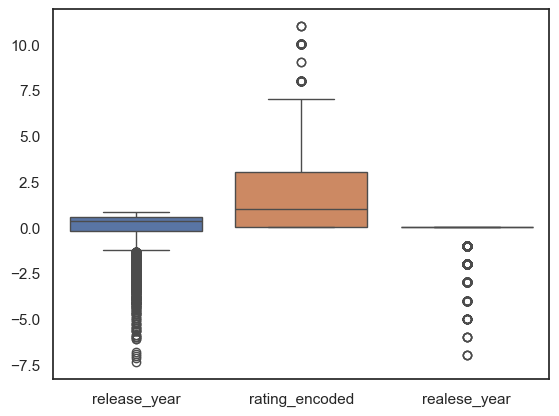

In [154]:
import seaborn as sns
sns.boxplot(df)

C:\Users\swarna\AppData\Local\Temp\ipykernel_11912\2036309486.py:13: UserWarning: Glyph 127916 (\N{CLAPPER BOARD}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\swarna\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127916 (\N{CLAPPER BOARD}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


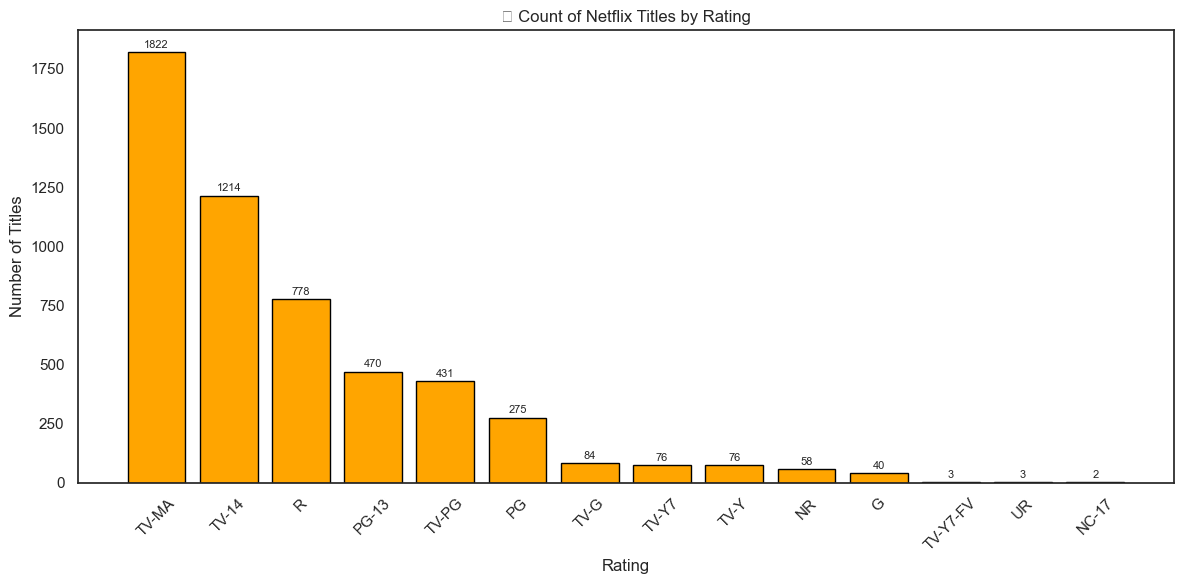

In [156]:
import pandas as pd
import matplotlib.pyplot as plt
rating_counts = df['rating'].value_counts().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
bars = plt.bar(rating_counts.index, rating_counts.values, color='orange', edgecolor='black')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 10, int(yval), ha='center', va='bottom', fontsize=8)
plt.title("🎬 Count of Netflix Titles by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


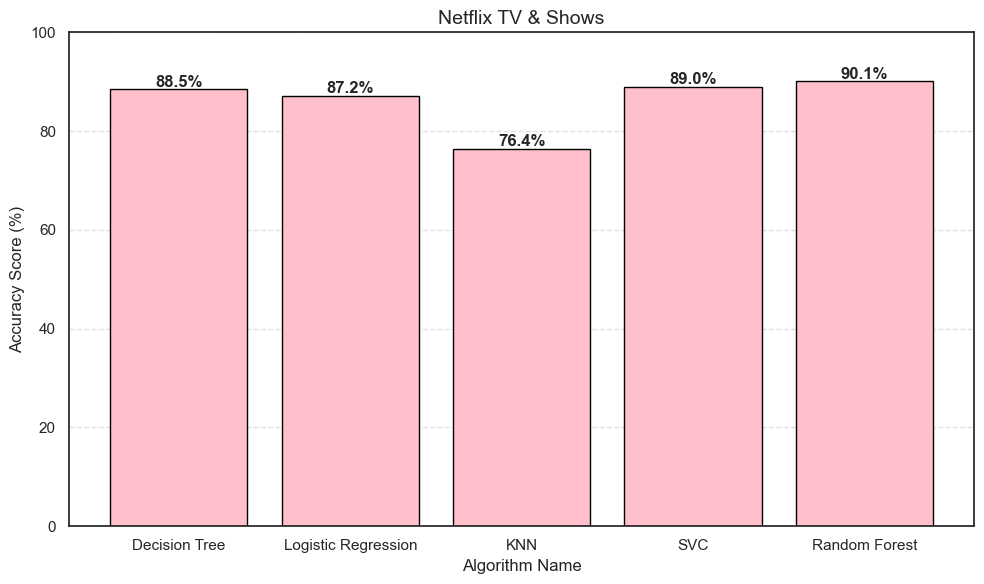

In [158]:
import matplotlib.pyplot as plt
algorithms = [
    'Decision Tree', 
    'Logistic Regression', 
    'KNN', 
    'SVC', 
    'Random Forest'
]
scores = [88.5, 87.2, 76.4, 89.0, 90.1]
plt.figure(figsize=(10, 6))
bars = plt.bar(algorithms, scores, color='pink', edgecolor='black')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.1f}%', ha='center', fontsize=12, fontweight='bold')
plt.xlabel('Algorithm Name', fontsize=12)
plt.ylabel('Accuracy Score (%)', fontsize=12)
plt.title('Netflix TV & Shows', fontsize=14)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


In [164]:
# on test data
from sklearn.metrics import confusion_matrix , classification_report
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_test_encoded = le.fit_transform(y_test)
y_pred_encoded = le.transform(y_pred)
cm=confusion_matrix(y_test_encoded,y_pred_encoded)
print(cm)
print(classification_report(y_test_encoded,y_pred_encoded,target_names=le.classes_))

[[  1   0   1   4   5   3   0   6   0   0   0   0   0]
 [  0   0   1   3   3   3   0  24   0   0   0   0   0]
 [  0   0   1  20  24  25   0  79   1   0   0   0   0]
 [  0   0   0  41  52  39   0  96   6   0   0   0   0]
 [  1   0   3  42  60  51   0 215   5   0   0   0   0]
 [  4   0   4  68  61  68   1 407   7   0   0   0   0]
 [  0   0   1   1   2   2   0  34   0   0   0   0   0]
 [  1   0   2  29  34  45   0 786   2   0   0   0   0]
 [  1   0   3  15  15  22   0 154   2   0   0   0   0]
 [  0   0   0   2   2   5   0  33   0   0   0   0   0]
 [  0   0   0   4   3   5   0  21   0   0   0   0   0]
 [  0   0   0   0   1   0   0   1   0   0   0   0   0]
 [  0   0   0   1   1   0   0   1   0   0   0   0   0]]
              precision    recall  f1-score   support

           G       0.12      0.05      0.07        20
          NR       0.00      0.00      0.00        34
          PG       0.06      0.01      0.01       150
       PG-13       0.18      0.18      0.18       234
           R 

C:\Users\swarna\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\swarna\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\swarna\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [166]:
# on train data
from sklearn.metrics import confusion_matrix , classification_report
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_pred_encoded = le.transform(y_pred)
cm=confusion_matrix(y_train_encoded,y_pred_encoded)
print(cm)
print(classification_report(y_train_encoded,y_pred_encoded,target_names=le.classes_))

[[  0   0   0   1   1   3   3   0  12   0   0   0   0]
 [  0   0   0   0   0   1   0   0   1   0   0   0   0]
 [  0   0   0   0   4   1   1   0  18   0   0   0   0]
 [  0   0   0   1   6  19  16   0  82   1   0   0   0]
 [  1   0   0   1  27  13  25   1 167   1   0   0   0]
 [  1   0   0   2  28  49  37   0 281   3   0   0   0]
 [  2   0   0   4  52  67  57   0 410   2   0   0   0]
 [  0   0   0   1   5   3   6   0  27   2   0   0   0]
 [  4   0   0   5  76  84  82   0 663   9   0   0   0]
 [  0   0   0   1  23  15  30   0 146   4   0   0   0]
 [  0   0   0   0   5   4   4   0  21   0   0   0   0]
 [  0   0   0   0   2   4   7   0  29   1   0   0   0]
 [  0   0   0   0   1   0   0   0   0   0   0   0   0]]
              precision    recall  f1-score   support

           G       0.00      0.00      0.00        20
       NC-17       0.00      0.00      0.00         2
          NR       0.00      0.00      0.00        24
          PG       0.06      0.01      0.01       125
       PG-13 

C:\Users\swarna\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\swarna\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\swarna\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [168]:
print(metrics.accuracy_score(y_train_encoded,y_pred)*100)
print(metrics.accuracy_score(y_test_encoded,y_pred)*100)

0.0
0.0


In [172]:
from sklearn.metrics import confusion_matrix,classification_report
y_true=[1,0,1,1,0,1,0,0,1,0]
y_pred=[1,0,1,0,0,1,1,0,1,0]
cm=confusion_matrix(y_true,y_pred)
print(cm)
print(classification_report(y_true,y_pred,target_names=['positive','negative']))

[[4 1]
 [1 4]]
              precision    recall  f1-score   support

    positive       0.80      0.80      0.80         5
    negative       0.80      0.80      0.80         5

    accuracy                           0.80        10
   macro avg       0.80      0.80      0.80        10
weighted avg       0.80      0.80      0.80        10



In [194]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
df = df.dropna(subset=['description', 'listed_in'])
sample_description = "A young woman discovers a shocking secret about her family and embarks on a dangerous journey to uncover the truth."
descriptions = df['description'].tolist()
descriptions.append(sample_description)
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(descriptions)
cosine_sim = cosine_similarity(tfidf_matrix[-1], tfidf_matrix[:-1])
most_similar_idx = cosine_sim.argmax()
predicted_genre = df.iloc[most_similar_idx]['listed_in']
print("Sample Description:\n", sample_description)
print("\nPredicted Genre:\n", predicted_genre)


Sample Description:
 A young woman discovers a shocking secret about her family and embarks on a dangerous journey to uncover the truth.

Predicted Genre:
 Comedies, International Movies, Romantic Movies
